# 🚄 Régularité des TGV : exploration des données

**Projet IADATA 700 · données SNCF Open Data**

Ce notebook explore la régularité mensuelle des TGV par liaison, puis prépare le croisement avec les données sur les gares et les lignes à grande vitesse.

### Jeux de données utilisés

| Jeu de données | Contenu | Identifiant |
|---|---|---|
| Régularité mensuelle TGV par liaisons (AQST) | Retards, annulations et causes de retard, par mois et par liaison | `regularite-mensuelle-tgv-aqst` |
| Liste des gares | Gares du réseau, avec leur ligne et leurs coordonnées | `liste-des-gares` |
| Lignes LGV et par écartement | Lignes ferroviaires et leur catégorie (`catlig`) | `lignes-lgv-et-par-ecartement` |
| Fréquentation en gares | Fréquentation des gares voyageurs | `frequentation-gares` |

> **Définition SNCF d'un train à l'heure** : retard au terminus inférieur à 5 min pour un parcours de moins de 1h30, 10 min entre 1h30 et 3h, 15 min au-delà de 3h.
> Les chiffres par liaison ne doivent pas être additionnés pour retrouver une régularité globale : un même TGV peut compter dans plusieurs liaisons.

### Plan

1. Imports et chargement
2. Qualité des données
3. Distribution des retards
4. Causes des retards
5. Liaisons et gares
6. Gares et lignes à grande vitesse
7. Nettoyage des noms de gares
8. Vérification : toutes les gares sont-elles dans la liste des gares ?
9. Synthèse et prochaines étapes
10. Traitement des points de la synthèse
11. Travaux complémentaires (sans attendre le dictionnaire de gares)
12. Prochaines étapes

## 1. Imports et chargement

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import squarify

from railinsight.data.loader import FREQUENTATION, GARES, LIGNES, REGULARITE, load

In [2]:
sns.set_theme(style="whitegrid", palette="Set2")

Chargement du jeu de données de régularité, directement depuis l'API SNCF (aucun fichier CSV n'est créé).

In [3]:
df_raw = load(REGULARITE)
print(df_raw.shape)
print(df_raw.head().to_markdown())

(12907, 26)
|    | date    | service   | gare_depart        | gare_arrivee       |   duree_moyenne |   nb_train_prevu |   nb_annulation |   commentaire_annulation |   nb_train_depart_retard |   retard_moyen_depart |   retard_moyen_tous_trains_depart |   commentaire_retards_depart |   nb_train_retard_arrivee |   retard_moyen_arrivee |   retard_moyen_tous_trains_arrivee | commentaires_retard_arrivee                                                      |   nb_train_retard_sup_15 |   retard_moyen_trains_retard_sup15 |   nb_train_retard_sup_30 |   nb_train_retard_sup_60 |   prct_cause_externe |   prct_cause_infra |   prct_cause_gestion_trafic |   prct_cause_materiel_roulant |   prct_cause_gestion_gare |   prct_cause_prise_en_charge_voyageurs |
|---:|:--------|:----------|:-------------------|:-------------------|----------------:|-----------------:|----------------:|-------------------------:|-------------------------:|----------------------:|----------------------------------:|------------

## 2. Qualité des données

Types, valeurs distinctes et valeurs manquantes pour chaque colonne.

In [4]:
df_infos = pd.DataFrame(
    {
        "type": df_raw.dtypes.astype(str),
        "valeurs_distinctes": df_raw.nunique(),
        "valeurs_nulles": df_raw.isnull().sum(),
        "pourcentage_manquant": (df_raw.isnull().mean() * 100).round(2),
    }
)

print(df_infos.to_markdown())


|                                      | type    |   valeurs_distinctes |   valeurs_nulles |   pourcentage_manquant |
|:-------------------------------------|:--------|---------------------:|-----------------:|-----------------------:|
| date                                 | str     |                  105 |                0 |                   0    |
| service                              | str     |                    2 |                0 |                   0    |
| gare_depart                          | str     |                   59 |                0 |                   0    |
| gare_arrivee                         | str     |                   59 |                0 |                   0    |
| duree_moyenne                        | int64   |                  411 |                0 |                   0    |
| nb_train_prevu                       | int64   |                  908 |                0 |                   0    |
| nb_annulation                        | int64   |      

**Constats**

- `commentaire_annulation` et `commentaire_retards_depart` sont **vides à 100 %** : colonnes à supprimer au nettoyage.
- `commentaires_retard_arrivee` est manquante à **94,6 %** : très peu exploitable.
- Aucune autre colonne n'a de valeur manquante.
- Le jeu compte 105 mois distincts, 2 types de service, et 59 gares de départ comme d'arrivée.

## 3. Distribution des retards

Retards moyens au départ et à l'arrivée, pour les trains en retard et pour l'ensemble des trains.

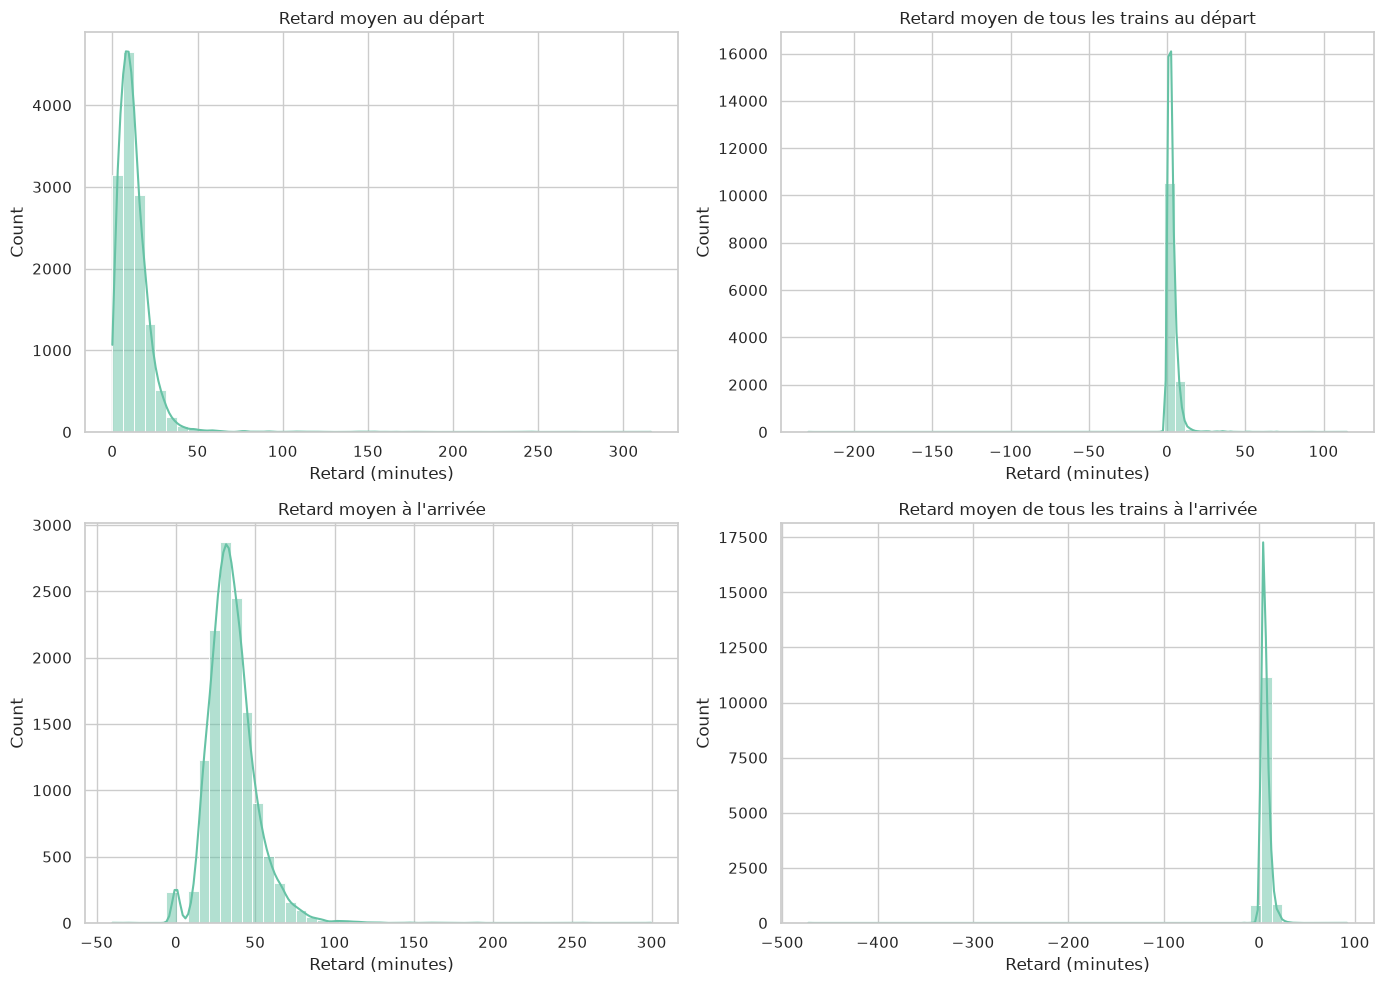

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- DÉPART ---

sns.histplot(data=df_raw, x="retard_moyen_depart", bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Retard moyen au départ")
axes[0, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_depart", bins=50, kde=True, ax=axes[0, 1]
)
axes[0, 1].set_title("Retard moyen de tous les trains au départ")
axes[0, 1].set_xlabel("Retard (minutes)")


# --- ARRIVÉE ---

sns.histplot(data=df_raw, x="retard_moyen_arrivee", bins=50, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Retard moyen à l'arrivée")
axes[1, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_arrivee", bins=50, kde=True, ax=axes[1, 1]
)
axes[1, 1].set_title("Retard moyen de tous les trains à l'arrivée")
axes[1, 1].set_xlabel("Retard (minutes)")


plt.tight_layout()
plt.show()

Valeur minimale du retard moyen à l'arrivée (tous trains) :

In [6]:
print(min(df_raw["retard_moyen_tous_trains_arrivee"]))

-472.6388889


> ⚠️ **Anomalie** : le minimum est très négatif (environ −472 min, soit près de 8 h d'avance). Un retard moyen ne peut pas atteindre une telle valeur : la SNCF n'est jamais en avance de cette ampleur. Ces valeurs aberrantes sont à traiter au nettoyage.

## 4. Causes des retards

Part moyenne de chaque cause sur l'ensemble du jeu de données. C'est une moyenne simple : elle n'est pas pondérée par le nombre de trains de chaque liaison.

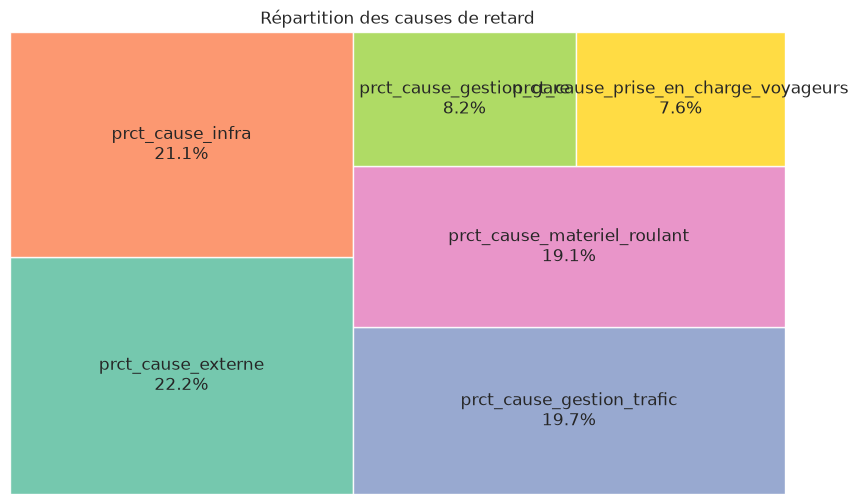

In [7]:
cols = [
    "prct_cause_externe",
    "prct_cause_infra",
    "prct_cause_gestion_trafic",
    "prct_cause_materiel_roulant",
    "prct_cause_gestion_gare",
    "prct_cause_prise_en_charge_voyageurs",
]

values = df_raw[cols].mean()

plt.figure(figsize=(10, 6))

squarify.plot(
    sizes=values,
    label=[f"{x}\n{y:.1f}%" for x, y in zip(cols, values)],
    color=sns.color_palette("Set2", 6),
    alpha=0.9,
)

plt.axis("off")
plt.title("Répartition des causes de retard")
plt.show()

## 5. Liaisons et gares

Couples distincts gare de départ / gare d'arrivée présents dans le jeu de données.

In [8]:
couples_gares = df_raw[['gare_depart', 'gare_arrivee']].drop_duplicates()
print(couples_gares.to_markdown())


|     | gare_depart                    | gare_arrivee                   |
|----:|:-------------------------------|:-------------------------------|
|   0 | BORDEAUX ST JEAN               | PARIS MONTPARNASSE             |
|   1 | LE MANS                        | PARIS MONTPARNASSE             |
|   2 | PARIS MONTPARNASSE             | LA ROCHELLE VILLE              |
|   3 | PARIS MONTPARNASSE             | NANTES                         |
|   4 | POITIERS                       | PARIS MONTPARNASSE             |
|   5 | ST MALO                        | PARIS MONTPARNASSE             |
|   6 | TOULOUSE MATABIAU              | PARIS MONTPARNASSE             |
|   7 | VANNES                         | PARIS MONTPARNASSE             |
|   8 | REIMS                          | PARIS EST                      |
|   9 | DOUAI                          | PARIS NORD                     |
|  10 | LILLE                          | PARIS NORD                     |
|  11 | LILLE                         

## 6. Gares et lignes à grande vitesse

**Question :** les liaisons circulent-elles sur les mêmes rails ? La réponse conditionne le nettoyage des données.

### Chargement des jeux de données sur les gares et les lignes

In [9]:
df_gares_raw = load(GARES)
print(df_gares_raw.shape)
print(df_gares_raw.head().to_markdown())

df_lines_raw = load(LIGNES)
print(df_lines_raw.shape)
print(df_lines_raw.head().to_markdown())

(6469, 18)
|    |   code_uic | libelle        | fret   | voyageurs   |   code_ligne |   rg_troncon | pk      | commune        | departemen          |   idreseau | idgaia                               |   x_l93 |       y_l93 |   x_wgs84 |   y_wgs84 | c_geo                                   | geo_point_2d                            | geo_shape                                                                  |
|---:|-----------:|:---------------|:-------|:------------|-------------:|-------------:|:--------|:---------------|:--------------------|-----------:|:-------------------------------------|--------:|------------:|----------:|----------:|:----------------------------------------|:----------------------------------------|:---------------------------------------------------------------------------|
|  0 |   87731448 | Porte Maillot  | N      | O           |       979000 |            1 | 005+500 | PARIS          | PARIS               |     109993 | 3964dfe0-0a8a-11ec-b1ff-01bcb2273146 

### Chargement de la fréquentation des gares

In [10]:
df_frequentation_raw = load(FREQUENTATION)
print(df_frequentation_raw.shape)
print(df_frequentation_raw.head().to_markdown())

(3021, 27)
|    | nom_gare           |   code_uic_complet |   code_postal | direction_regionale_gares   | segmentation_drg   | segmentation_marketing   |   non_voyageurs |   total_voyageurs_2024 |   total_voyageurs_non_voyageurs_2024 |   total_voyageurs_2023 |   total_voyageurs_non_voyageurs_2023 |   total_voyageurs_2022 |   total_voyageurs_non_voyageurs_2022 |   total_voyageurs_2021 |   total_voyageurs_non_voyageurs_2021 |   total_voyageurs_2020 |   total_voyageurs_non_voyageurs_2020 |   total_voyageurs_2019 |   total_voyageurs_non_voyageurs_2019 |   total_voyageurs_2018 |   total_voyageurs_non_voyageurs_2018 |   totalvoyageurs2017 |   total_voyageurs_non_voyageurs_2017 |   total_voyageurs_2016 |   total_voyageurs_non_voyageurs_2016 |   total_voyageurs_2015 |   total_voyageurs_non_voyageurs_2015 |
|---:|:-------------------|-------------------:|--------------:|:----------------------------|:-------------------|:-------------------------|----------------:|-----------------------:|-----

### Filtre sur les lignes à grande vitesse

On garde les lignes de catégorie « Ligne à grande vitesse », puis les gares situées sur ces lignes.

In [11]:
df_gares_raw[df_gares_raw["libelle"] == "Bordeaux-St-Jean"]

,code_uic,libelle,fret,voyageurs,code_ligne,rg_troncon,pk,commune,departemen,idreseau,idgaia,x_l93,y_l93,x_wgs84,y_wgs84,c_geo,geo_point_2d,geo_shape
1761,87581009,Bordeaux-St-Jean,O,O,655000,1,000+000,BORDEAUX,GIRONDE,113151,e001860e-19bf-11e5-82ff-01fc64e0362d,419015.4944,6.420413e+06,-0.555978,44.825923,"44.82592310199666, -0.5559775161877916","44.825923101976585, -0.5559775161877943","{""coordinates"": [-0.555977516187794, 44.825923..."
1833,87581009,Bordeaux-St-Jean,O,O,570000,3,583+844,BORDEAUX,GIRONDE,113551,e001860e-19bf-11e5-82ff-01fc64e0362d,419019.7653,6.420426e+06,-0.555931,44.826041,"44.82604094019732, -0.5559308913518892","44.82604094017726, -0.5559308913518917","{""coordinates"": [-0.555930891351892, 44.826040..."
5923,87581009,Bordeaux-St-Jean,O,O,640000,1,000+000,BORDEAUX,GIRONDE,114494,e001860e-19bf-11e5-82ff-01fc64e0362d,419015.4944,6.420413e+06,-0.555978,44.825923,"44.82592310199666, -0.5559775161877916","44.825923101976585, -0.5559775161877943","{""coordinates"": [-0.555977516187794, 44.825923..."


In [12]:
df_lines_raw[df_lines_raw["code_ligne"] == 655000]

,code_ligne,lib_ligne,catlig,rg_troncon,pkd,pkf,idgaia,x_d_l93,y_d_l93,x_f_l93,y_f_l93,x_d_wgs84,y_d_wgs84,x_f_wgs84,y_f_wgs84,c_geo_d,c_geo_f,geo_point_2d,geo_shape
39,655000,655000,Ligne du réseau conventionnel à écartement normal,1,000+000,235+063,777b3842-e28c-11e8-92ff-01b064e0362d,419015.4944,6.420413e+06,310545.8681,6.260623e+06,-0.555978,44.825923,-1.802873,43.33812,"44.82592310199666, -0.5559775161877916","43.33811986489555, -1.802873494508197","44.02377137626735, -1.1103676334588324","{""coordinates"": [[-0.555977516187794, 44.82592..."
1550,655000,655000,Ligne du réseau conventionnel à écartement normal,1,NaN,NaN,NaN,419015.4944,6.420413e+06,310545.8681,6.260623e+06,-0.555978,44.825923,-1.802873,43.33812,"44.82592310199666, -0.5559775161877916","43.33811986489555, -1.802873494508197","44.02377137626735, -1.1103676334588324","{""coordinates"": [[-0.555977516187794, 44.82592..."


In [13]:
df_lgv = df_lines_raw[df_lines_raw["catlig"] == "Ligne à grande vitesse"]
numeros_lgv = df_lgv["code_ligne"].unique()
df_gares_lgv_raw = df_gares_raw[df_gares_raw["code_ligne"].isin(numeros_lgv)]

print(df_gares_lgv_raw.to_markdown())
df_gares_lgv_raw.shape

|      |   code_uic | libelle                        | fret   | voyageurs   |   code_ligne |   rg_troncon | pk      | commune            | departemen            |   idreseau | idgaia                               |   x_l93 |       y_l93 |   x_wgs84 |   y_wgs84 | c_geo                                  | geo_point_2d                           | geo_shape                                                                 |
|-----:|-----------:|:-------------------------------|:-------|:------------|-------------:|-------------:|:--------|:-------------------|:----------------------|-----------:|:-------------------------------------|--------:|------------:|----------:|----------:|:---------------------------------------|:---------------------------------------|:--------------------------------------------------------------------------|
|  352 |   87171926 | Champagne-Ardenne-TGV          | N      | O           |         5000 |            1 | 113+767 | BEZANNES           | MARNE              

(31, 18)

## 7. Nettoyage des noms de gares

Les noms de gares ne s'écrivent pas de la même façon dans les deux sources (par exemple `Lyon-St-Exupéry-TGV` dans la liste des gares). Pour pouvoir les comparer, on applique la même normalisation aux deux :

- tout en **majuscules** ;
- **accents supprimés** (`É` devient `E`) ;
- **tirets remplacés par des espaces** ;
- espaces multiples et espaces en début ou fin de nom supprimés.

Les jeux bruts (`df_raw`, `df_gares_raw`) ne sont pas modifiés : on travaille sur des copies.

In [14]:
from railinsight.data.quality import normaliser_noms

In [15]:
df_regularite = df_raw.copy()
for col in ["gare_depart", "gare_arrivee"]:
    df_regularite[col] = normaliser_noms(df_regularite[col])

df_gares_lgv_cleaned = df_gares_lgv_raw.copy()
df_gares_lgv_cleaned["gare"] = normaliser_noms(df_gares_lgv_cleaned["libelle"])

Vérification visuelle : quelques noms avant et après normalisation.

In [16]:
df_gares_lgv_cleaned[["libelle", "gare"]].drop_duplicates()

,libelle,gare
352,Champagne-Ardenne-TGV,CHAMPAGNE ARDENNE
424,Valence-TGV,VALENCE
563,Besançon-Franche-Comté-TGV,BESANCON FRANCHE COMTE
775,Lyon-St-Exupéry-TGV,LYON ST EXUPERY
788,Vendôme-Villiers-sur-Loir,VENDOME VILLIERS SUR LOIR
822,Lyon-St-Clair,LYON ST CLAIR
1247,Allan,ALLAN
1547,Pasilly,PASILLY
1846,Senas-TGV,SENAS
1876,Avignon-TGV,AVIGNON


## 8. Vérification : toutes les gares sont-elles dans la liste des gares ?

1. On regroupe les gares de départ et d'arrivée dans une seule colonne.
2. On garde les valeurs distinctes.
3. On fusionne (`merge`) avec la liste des gares : l'option `indicator=True` ajoute une colonne `_merge` qui indique si la gare a été trouvée (`both`) ou non (`left_only`).

In [17]:
gares_regularite = (
    pd.concat([df_regularite["gare_depart"], df_regularite["gare_arrivee"]])
    .dropna()
    .drop_duplicates()
    .sort_values()
    .to_frame(name="gare")
    .reset_index(drop=True)
)
print(f"{len(gares_regularite)} gares distinctes dans le jeu de régularité")

59 gares distinctes dans le jeu de régularité


In [18]:
verif = gares_regularite.merge(
    df_gares_lgv_cleaned[["gare"]].drop_duplicates(),
    on="gare",
    how="left",
    indicator=True,
)

manquantes = verif.loc[verif["_merge"] == "left_only", ["gare"]].reset_index(drop=True)

print(f"Trouvées : {(verif['_merge'] == 'both').sum()} / {len(verif)}")
print(f"Absentes de la liste des gares : {len(manquantes)}")
manquantes

Trouvées : 5 / 59
Absentes de la liste des gares : 54


,gare
0,ANGERS ST LAUD
1,ANGOULEME
2,ANNECY
3,ARRAS
4,BARCELONA
5,BELLEGARDE (AIN)
6,BORDEAUX ST JEAN
7,BREST
8,CHAMBERY CHALLES LES EAUX
9,DIJON VILLE


Une gare absente n'est pas forcément une erreur. Deux explications sont probables, à confirmer avec la liste ci-dessus :

- **Gares étrangères** : `BARCELONA`, `MADRID`, `FRANCFORT`, `ZURICH`, `GENEVE`... figurent dans les liaisons mais ne sont sans doute pas dans une liste de gares françaises.
- **Noms différents d'une source à l'autre** : par exemple `PARIS LYON` côté régularité, probablement un autre libellé côté liste des gares. Ces cas se règlent avec un dictionnaire de correspondance, à construire à partir de la liste des gares absentes.

## 9. Synthèse et prochaines étapes

- [ ] Supprimer les colonnes vides (`commentaire_annulation`, `commentaire_retards_depart`).
- [ ] Traiter les retards moyens négatifs aberrants.
- [ ] Construire un dictionnaire de correspondance pour les gares absentes de la liste des gares.
- [ ] Décider du traitement des gares étrangères.
- [ ] Déplacer `normaliser_noms` dans `src/` pour la réutiliser dans les autres notebooks.

## 10. Traitement des points de la synthèse

### 10.1 Supprimer les colonnes vides

`commentaire_annulation` et `commentaire_retards_depart` sont vides à 100 % (section 2) : elles n'apportent aucune information et sont supprimées. `commentaires_retard_arrivee` (94,6 % manquant) est conservée pour l'instant : le cadrage ne demande pas sa suppression, mais elle reste trop creuse pour être exploitée telle quelle.


In [19]:
colonnes_vides = ["commentaire_annulation", "commentaire_retards_depart"]

print("Avant :", list(df_regularite.columns[df_regularite.columns.isin(colonnes_vides)]))

df_regularite = df_regularite.drop(columns=colonnes_vides)

print("Après : colonnes présentes ?", any(c in df_regularite.columns for c in colonnes_vides))
print(df_regularite.shape)


Avant : ['commentaire_annulation', 'commentaire_retards_depart']
Après : colonnes présentes ? False
(12907, 24)


### 10.2 Traiter les retards moyens négatifs aberrants

Un retard moyen négatif de plusieurs centaines de minutes est physiquement impossible (section 3, minimum ≈ −472 min). On mesure d'abord l'ampleur du problème sur les quatre colonnes de retard moyen, puis on neutralise les valeurs négatives en les ramenant à 0 (un retard moyen ne peut pas être inférieur à 0). On choisit de **clipper** plutôt que de supprimer les lignes, pour ne pas perdre les autres informations (causes, annulations) de ces liaisons/mois.


In [20]:
colonnes_retard = [
    "retard_moyen_depart",
    "retard_moyen_tous_trains_depart",
    "retard_moyen_arrivee",
    "retard_moyen_tous_trains_arrivee",
]

negatifs = (df_regularite[colonnes_retard] < 0).sum()
print("Nombre de valeurs négatives par colonne :")
print(negatifs.to_markdown())

for col in colonnes_retard:
    df_regularite[col] = df_regularite[col].clip(lower=0)

print("\nVérification après traitement :")
print((df_regularite[colonnes_retard] < 0).sum().to_markdown())


Nombre de valeurs négatives par colonne :
|                                  |   0 |
|:---------------------------------|----:|
| retard_moyen_depart              |   0 |
| retard_moyen_tous_trains_depart  | 170 |
| retard_moyen_arrivee             |   2 |
| retard_moyen_tous_trains_arrivee | 122 |

Vérification après traitement :
|                                  |   0 |
|:---------------------------------|----:|
| retard_moyen_depart              |   0 |
| retard_moyen_tous_trains_depart  |   0 |
| retard_moyen_arrivee             |   0 |
| retard_moyen_tous_trains_arrivee |   0 |


### 10.3 Dictionnaire de correspondance pour les gares absentes

Sur les 55 gares absentes de la liste des gares LGV (section 8), une partie correspond à des **gares françaises bien réelles mais nommées différemment** d'une source à l'autre (ex. `PARIS LYON` vs un libellé du type `PARIS GARE DE LYON` dans la liste des gares, `BORDEAUX ST JEAN` vs `BORDEAUX-ST-JEAN`, etc.). Une autre partie correspond à des **gares étrangères**, traitées au point suivant.

**Méthode envisagée** (à finaliser en groupe) :

1. Repartir de la liste `manquantes` déjà calculée en section 8.
2. Pour chaque gare manquante, chercher dans `df_gares_raw` (liste complète, avant filtre LGV) un libellé proche, car la gare existe peut-être simplement sur une ligne non classée « Ligne à grande vitesse » (cas probable pour beaucoup de gares de la liste : `NANTES`, `RENNES`, `STRASBOURG`... qui ne sont pas forcément sur des lignes LGV au sens strict).
3. Pour les gares non trouvées même dans la liste complète, comparer manuellement les libellés (éventuellement à l'aide d'un rapprochement approximatif du type distance de Levenshtein ou `difflib.get_close_matches`, à décider en groupe) et valider chaque correspondance à la main plutôt que de l'automatiser aveuglément.
4. Construire un dictionnaire `{nom_normalisé_regularite: nom_normalisé_liste_gares}` et l'appliquer à `df_regularite` avant toute jointure.
5. Documenter chaque correspondance retenue dans la `DATASHEET.md`, pour tracer les décisions de nettoyage comme demandé dans le cadrage.

discussion colléctives pour décider 


### 10.4 Décider du traitement des gares étrangères

D'après la liste `manquantes`, les gares clairement étrangères sont : `BARCELONA`, `MADRID`, `FRANCFORT`, `GENEVE`, `LAUSANNE`, `STUTTGART`, `ZURICH`, `ITALIE`. Le cadrage indique que les liaisons internationales sont « gardées ou non selon leur part du volume de trains, à mesurer ». On mesure donc cette part avant de trancher, plutôt que de les exclure par défaut.


In [21]:
gares_etrangeres = [
    "BARCELONA", "MADRID", "FRANCFORT", "GENEVE",
    "LAUSANNE", "STUTTGART", "ZURICH", "ITALIE",
]

est_internationale = (
    df_regularite["gare_depart"].isin(gares_etrangeres)
    | df_regularite["gare_arrivee"].isin(gares_etrangeres)
)

part_lignes = est_internationale.mean() * 100
part_trains = (
    df_regularite.loc[est_internationale, "nb_train_prevu"].sum()
    / df_regularite["nb_train_prevu"].sum()
    * 100
)

print(f"Part des lignes (mois x liaison) internationales : {part_lignes:.2f} %")
print(f"Part du volume de trains prévus concernés : {part_trains:.2f} %")


Part des lignes (mois x liaison) internationales : 12.01 %
Part du volume de trains prévus concernés : 5.16 %


### 10.5 Déplacer `normaliser_noms` dans `src/`

La fonction est déplacée dans `railinsight/data/quality.py`, aux côtés de `missing_report` et `outlier_flags` (module déjà dédié à la qualité des données). La cellule de la section 7 a été mise à jour pour l'importer (`from railinsight.data.quality import normaliser_noms`) au lieu de la redéfinir localement, afin qu'elle soit réutilisable dans les autres notebooks et dans l'application Streamlit.


## 11. Travaux complémentaires (sans attendre le dictionnaire de gares)

Les points suivants des prochaines étapes ne dépendent pas de la correspondance des noms de gares (point 10.3) et peuvent être traités dès maintenant.

### 11.1 Contrôler la somme des causes

Le cadrage (Phase 0) demande de vérifier que les six `prct_cause_*` totalisent environ 100 % par ligne, pour détecter d'éventuels faux zéros.

In [22]:
cols_causes = [
    "prct_cause_externe",
    "prct_cause_infra",
    "prct_cause_gestion_trafic",
    "prct_cause_materiel_roulant",
    "prct_cause_gestion_gare",
    "prct_cause_prise_en_charge_voyageurs",
]

somme_causes = df_regularite[cols_causes].sum(axis=1)

print(somme_causes.describe().to_markdown())

hors_tolerance = (somme_causes - 100).abs() > 1
print(f"\nLignes hors tolérance (±1 point autour de 100) : {hors_tolerance.sum()} / {len(df_regularite)}")
print(f"Soit {hors_tolerance.mean() * 100:.2f} % des lignes")


|       |          0 |
|:------|-----------:|
| count | 12907      |
| mean  |    97.8886 |
| std   |    14.3646 |
| min   |     0      |
| 25%   |   100      |
| 50%   |   100      |
| 75%   |   100      |
| max   |   100      |

Lignes hors tolérance (±1 point autour de 100) : 281 / 12907
Soit 2.18 % des lignes


In [23]:
zero_causes = somme_causes == 0
print(f"Lignes à 0 % de causes : {zero_causes.sum()}")
print(
    "Parmi elles, part sans aucun train en retard à l'arrivée : "
    f"{(df_regularite.loc[zero_causes, 'nb_train_retard_arrivee'] == 0).mean() * 100:.1f} %"
)


Lignes à 0 % de causes : 272
Parmi elles, part sans aucun train en retard à l'arrivée : 70.6 %


**Constat** : la somme vaut 100 pour la médiane et les trois quartiles ; seules 2,18 % des lignes s'écartent de plus de 1 point. Sur ces lignes, 70,6 % correspondent simplement à des mois sans aucun train en retard (donc 0 % de cause déclarée, ce qui est normal). Les 29,4 % restants (environ 80 lignes) sont de vrais écarts à surveiller, mais ne remettent pas en cause l'ensemble du jeu de données.

### 11.2 Seuil et volume minimal pour les liaisons « durablement en difficulté »

Le cadrage définit 3 classes de durée de trajet (`duree_moyenne`, en minutes) avec un seuil de retard différent à chaque fois : moins de 1 h 30 (5 min), 1 h 30–3 h (10 min), plus de 3 h (15 min). On construit ces classes, puis on regarde par classe la distribution du taux de retard agrégé par liaison et par an, pondéré par le nombre de trains.

> ⚠️ Le jeu de données expose `nb_train_retard_arrivee` (nombre de trains en retard à l'arrivée), sans préciser le seuil exact utilisé par la SNCF pour ce comptage. On l'utilise ici comme approximation du taux de retard ; le seuil par classe de durée (5/10/15 min) devra être appliqué finement si un recalcul à partir de données plus fines devient nécessaire.


In [24]:
def classer_duree(minutes: pd.Series) -> pd.Series:
    """Classe de durée de trajet selon les seuils du cadrage."""
    return pd.cut(
        minutes,
        bins=[-1, 90, 180, minutes.max() + 1],
        labels=["< 1h30", "1h30-3h", "> 3h"],
    )


df_regularite["annee"] = df_regularite["date"].str[:4].astype(int)
df_regularite["classe_duree"] = classer_duree(df_regularite["duree_moyenne"])

print(df_regularite["classe_duree"].value_counts().sort_index().to_markdown())


| classe_duree   |   count |
|:---------------|--------:|
| < 1h30         |    2202 |
| 1h30-3h        |    5534 |
| > 3h           |    5171 |


In [25]:
agg_liaison_annee = (
    df_regularite.groupby(
        ["gare_depart", "gare_arrivee", "annee", "classe_duree"], observed=True
    )
    .agg(
        nb_train_prevu=("nb_train_prevu", "sum"),
        nb_train_retard_arrivee=("nb_train_retard_arrivee", "sum"),
    )
    .reset_index()
)
agg_liaison_annee["taux_retard"] = (
    agg_liaison_annee["nb_train_retard_arrivee"] / agg_liaison_annee["nb_train_prevu"]
)

print(f"{len(agg_liaison_annee)} lignes liaison x année x classe de durée")
print(
    agg_liaison_annee.groupby("classe_duree", observed=True)["taux_retard"]
    .describe()
    .to_markdown()
)


1249 lignes liaison x année x classe de durée
| classe_duree   |   count |     mean |       std |       min |      25% |      50% |      75% |      max |
|:---------------|--------:|---------:|----------:|----------:|---------:|---------:|---------:|---------:|
| < 1h30         |     195 | 0.15199  | 0.0520777 | 0.037037  | 0.115244 | 0.148293 | 0.183652 | 0.48     |
| 1h30-3h        |     514 | 0.139237 | 0.0522775 | 0.0490196 | 0.100901 | 0.127314 | 0.16333  | 0.357534 |
| > 3h           |     491 | 0.149157 | 0.0638396 | 0         | 0.104173 | 0.140351 | 0.179672 | 0.553425 |


In [26]:
seuils_candidats = agg_liaison_annee.groupby("classe_duree", observed=True)[
    "taux_retard"
].quantile(0.75)
print("Seuils candidats (quartile supérieur du taux de retard par classe) :")
print(seuils_candidats.to_markdown())

print("\nDistribution du volume annuel de trains par liaison (toutes classes confondues) :")
print(agg_liaison_annee["nb_train_prevu"].describe().to_markdown())

volume_min_candidat = agg_liaison_annee["nb_train_prevu"].quantile(0.10)
print(f"\nVolume minimal candidat (10e percentile) : {volume_min_candidat:.0f} trains/an")
print(
    "Part des lignes liaison x année écartées à ce seuil : "
    f"{(agg_liaison_annee['nb_train_prevu'] < volume_min_candidat).mean() * 100:.1f} %"
)


Seuils candidats (quartile supérieur du taux de retard par classe) :
| classe_duree   |   taux_retard |
|:---------------|--------------:|
| < 1h30         |      0.183652 |
| 1h30-3h        |      0.16333  |
| > 3h           |      0.179672 |

Distribution du volume annuel de trains par liaison (toutes classes confondues) :
|       |   nb_train_prevu |
|:------|-----------------:|
| count |          1249    |
| mean  |          2825.73 |
| std   |          2187.07 |
| min   |             0    |
| 25%   |          1223    |
| 50%   |          2438    |
| 75%   |          3648    |
| max   |         12711    |

Volume minimal candidat (10e percentile) : 358 trains/an
Part des lignes liaison x année écartées à ce seuil : 10.0 %


**Proposition à valider en groupe** : seuil de retard autour de 0,16–0,18 selon la classe de durée (quartile supérieur de la distribution), et volume minimal autour de 350–400 trains par an et par liaison (10e percentile), ce qui exclut 10 % des liaisons les plus confidentielles. Ces valeurs sont des points de départ ; elles devront être recalculées une fois le dictionnaire de correspondance des gares appliqué (certaines liaisons sont peut-être sous-comptées à cause de doublons de noms).

### 11.3 Bornes des périodes de référence et de suivi

Le jeu de données couvre `2018-01` à `2026-09`. Le score de fiabilité (cadrage §3) porte sur les 12 derniers mois ; l'étude des liaisons en difficulté (Phase 2) compare une période de référence à une période de suivi, à saison égale.


In [27]:
date_min = df_regularite["date"].min()
date_max = df_regularite["date"].max()

derniers_12_mois = pd.period_range(end=date_max, periods=12, freq="M")
print(f"Période couverte : {date_min} -> {date_max}")
print(f"Score de fiabilité (12 derniers mois) : {derniers_12_mois[0]} -> {derniers_12_mois[-1]}")

# Proposition : période de suivi = 12 derniers mois, période de référence = les 3 années pleines
# qui précèdent, à saison égale (mêmes mois calendaires sur un nombre entier d'années).
suivi_debut, suivi_fin = derniers_12_mois[0], derniers_12_mois[-1]
reference_fin = suivi_debut - 1
reference_debut = reference_fin - 35  # 3 ans pleins avant la période de suivi

print(f"\nProposition période de référence : {reference_debut} -> {reference_fin}")
print(f"Proposition période de suivi      : {suivi_debut} -> {suivi_fin}")


Période couverte : 2018-01 -> 2026-09
Score de fiabilité (12 derniers mois) : 2025-10 -> 2026-09

Proposition période de référence : 2022-10 -> 2025-09
Proposition période de suivi      : 2025-10 -> 2026-09


### 11.4 Repérer les années atypiques

On regarde le volume total de trains prévus par an (sans faire de total réseau au sens strict : c'est juste une somme à but exploratoire, pour repérer les creux) et le taux de retard moyen pondéré par an, pour identifier les années à signaler (crise sanitaire 2020-2021, mouvements sociaux).


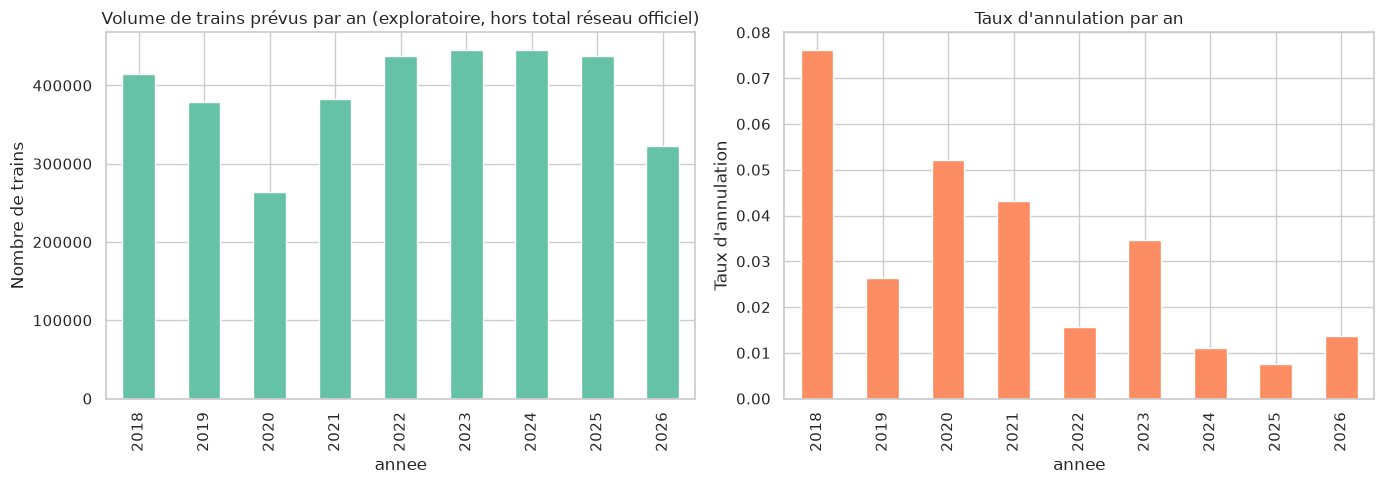

|   annee |   nb_train_prevu |   nb_train_retard_arrivee |   nb_annulation |   taux_retard |   taux_annulation |
|--------:|-----------------:|--------------------------:|----------------:|--------------:|------------------:|
|    2018 |           414653 |                     68199 |           31600 |      0.164472 |        0.0762083  |
|    2019 |           378790 |                     51012 |            9955 |      0.134671 |        0.0262811  |
|    2020 |           263853 |                     31079 |           13754 |      0.117789 |        0.0521275  |
|    2021 |           383087 |                     41341 |           16519 |      0.107915 |        0.0431208  |
|    2022 |           437705 |                     61739 |            6862 |      0.141052 |        0.0156772  |
|    2023 |           445544 |                     63119 |           15482 |      0.141667 |        0.0347485  |
|    2024 |           444878 |                     60218 |            4886 |      0.135358 |    

In [28]:
par_annee = (
    df_regularite.groupby("annee")
    .agg(
        nb_train_prevu=("nb_train_prevu", "sum"),
        nb_train_retard_arrivee=("nb_train_retard_arrivee", "sum"),
        nb_annulation=("nb_annulation", "sum"),
    )
    .assign(
        taux_retard=lambda d: d["nb_train_retard_arrivee"] / d["nb_train_prevu"],
        taux_annulation=lambda d: d["nb_annulation"] / d["nb_train_prevu"],
    )
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
par_annee["nb_train_prevu"].plot(kind="bar", ax=axes[0], color=sns.color_palette("Set2")[0])
axes[0].set_title("Volume de trains prévus par an (exploratoire, hors total réseau officiel)")
axes[0].set_ylabel("Nombre de trains")

par_annee["taux_annulation"].plot(kind="bar", ax=axes[1], color=sns.color_palette("Set2")[1])
axes[1].set_title("Taux d'annulation par an")
axes[1].set_ylabel("Taux d'annulation")

plt.tight_layout()
plt.show()

print(par_annee.to_markdown())


**Années à signaler** (à confirmer/affiner en groupe) :

- **2018** : taux d'annulation très élevé (7,6 %, le plus haut de la série) — grève SNCF du printemps 2018.
- **2020** : net creux de volume (263 853 trains, −30 % vs 2019) — confinements liés au Covid-19.
- **2021** : volume encore réduit et taux de retard anormalement bas (10,8 %) — reprise partielle post-Covid, moins de trafic donc moins de contraintes réseau.
- **2023** : pic d'annulations (3,5 %) — mouvements sociaux (réforme des retraites).
- **2026** : année partielle (seulement jusqu'à septembre), le volume plus faible est un artefact de troncature et non une anomalie réelle — à exclure des comparaisons annuelles tant que l'année n'est pas complète.

**Proposition** : signaler 2018, 2020, 2021 et 2023 comme années atypiques (ni les exclure ni les ignorer silencieusement), et traiter 2026 comme une année incomplète plutôt qu'atypique.


## Bilan de ce qu'on a fait jusqu'ici

En gros, on est partis d'un jeu de données brut pas super propre, et on l'a nettoyé + on a commencé à répondre à des questions du cadrage, sans attendre la partie la plus galère (faire correspondre les noms de gares entre les deux sources).

**Ce qu'on a nettoyé (section 10)** :
- On a viré 2 colonnes qui étaient vides à 100 % (`commentaire_annulation`, `commentaire_retards_depart`), elles servaient à rien.
- On a corrigé des retards moyens négatifs complètement absurdes (jusqu'à -472 min, soit 8h d'avance... un train n'est jamais autant en avance). On les a juste ramenés à 0 plutôt que de supprimer les lignes, pour pas perdre d'infos.
- On a mesuré que les gares étrangères (Barcelone, Madrid, Zurich...) représentent 12 % des liaisons mais seulement 5 % du vrai volume de trains, ce qui donne un chiffre concret pour décider si on les garde.
- On a déplacé la fonction `normaliser_noms` dans le code source (`railinsight/data/quality.py`) au lieu de la laisser dans le notebook, comme ça elle est réutilisable ailleurs (autres notebooks, appli Streamlit).

**Ce qu'on a vérifié / calculé en plus (section 11)**, sans avoir besoin du dictionnaire de gares :
- La somme des 6 causes de retard fait bien ~100 % dans l'immense majorité des cas (97,9 % en moyenne, seulement 2 % de lignes bizarres, et la plupart s'expliquent juste par l'absence de retard ce mois-là). Donc les données sur les causes sont fiables.
- On a proposé des premiers seuils chiffrés pour dire qu'une liaison est "en difficulté" (environ 16-18 % de retard selon que le trajet est court/moyen/long), et un volume minimal de trains à avoir pour qu'une liaison compte.
- On a proposé des dates concrètes pour comparer une "période de référence" à une "période de suivi" (les 12 derniers mois vs les 3 années d'avant).
- On a repéré les années bizarres dans les données : 2018 (grève), 2020-2021 (Covid), 2023 (grève retraites), et 2026 qui est juste incomplète (pas encore finie).

**Est-ce que ça colle avec le but du cadrage ?**
Oui, complètement : le cadrage demandait explicitement de faire tout ça en Phase 0 (nettoyer, vérifier la qualité) avant de pouvoir répondre à la vraie question directrice ("d'où viennent les retards ?"). On n'a pas encore attaqué le cœur du sujet (découper les retards par cause Réseau/Voyageurs/Externe), mais on a posé des bases saines et chiffrées pour le faire sérieusement. Les seuils et périodes qu'on propose ne sont pas gravés dans le marbre : le cadrage dit bien que ça doit être "confirmé sur la distribution", donc c'est fait pour être discuté en groupe, pas imposé.


## 12. Prochaines étapes

D'après le document de cadrage (`documentation/cadrage_question_directrice.md`), au-delà de tout ce qui a été traité dans les sections 10 et 11 :

- [ ] **Finaliser le dictionnaire de correspondance des gares** (point 10.3) et l'appliquer à `df_regularite` avant toute jointure avec la liste des gares — en discussion collective avec le groupe.
- [ ] **Trancher définitivement sur les gares étrangères** : la part mesurée (point 10.4) est de 12 % des lignes mais seulement 5,16 % du volume réel de trains, ce qui laisse penser qu'on peut les garder avec un simple indicateur, à valider en groupe.
- [ ] **Valider en groupe les seuils proposés** (point 11.2) pour les liaisons « durablement en difficulté » : ~0,16–0,18 de taux de retard selon la classe de durée, volume minimal ~358 trains/an.
- [ ] **Valider les bornes de périodes proposées** (point 11.3) : référence `2022-10` → `2025-09`, suivi `2025-10` → `2026-09`.
- [ ] **Décider du traitement des années atypiques repérées** (point 11.4) : 2018, 2020, 2021, 2023 à signaler ; 2026 à traiter comme année incomplète.
- [ ] **Passer à la Phase 1** du cadrage : calculer, pour chaque liaison, les contributions Réseau / Voyageurs / Externe (taux de retard × part de la cause), puis la distribution des liaisons selon leur cause dominante.
- [ ] **Recalculer les seuils et agrégats** une fois le dictionnaire de gares appliqué, car certaines liaisons sont peut-être actuellement sous-comptées à cause de doublons de noms non résolus.
- [ ] **Consigner chaque décision de nettoyage et chaque choix de seuil** dans la `DATASHEET.md` (7 sections), comme demandé en Phase 0 du cadrage.
